In [1]:
#imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
#sample dataset
data = {
    'Height': [150, 160, 165, 170, 175, 180, 185, 190],
    'Weight': [50, 55, 60, 65, 70, 75, 80, 85],
    'Age':    [20, 22, 25, 28, 30, 35, 40, 45],
    'Score':  [60, 65, 70, 75, 80, 85, 90, 95]
}
df = pd.DataFrame(data)
df

,Height,Weight,Age,Score
0,150,50,20,60
1,160,55,22,65
2,165,60,25,70
3,170,65,28,75
4,175,70,30,80
5,180,75,35,85
6,185,80,40,90
7,190,85,45,95


In [3]:
#dataframe info
print("Shape of dataset:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nDataset information:")
print(df.info())
print("\nStatistical summary:")
display(df.describe())

Shape of dataset: (8, 4)

Column names:
['Height', 'Weight', 'Age', 'Score']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Height  8 non-null      int64
 1   Weight  8 non-null      int64
 2   Age     8 non-null      int64
 3   Score   8 non-null      int64
dtypes: int64(4)
memory usage: 384.0 bytes
None

Statistical summary:


,Height,Weight,Age,Score
count,8.000000,8.000000,8.000000,8.000000
mean,171.875000,67.500000,30.625000,77.500000
std,13.346348,12.247449,8.782084,12.247449
min,150.000000,50.000000,20.000000,60.000000
25%,163.750000,58.750000,24.250000,68.750000
50%,172.500000,67.500000,29.000000,77.500000
75%,181.250000,76.250000,36.250000,86.250000
max,190.000000,85.000000,45.000000,95.000000


In [4]:
#feature selection for pca
X = df[['Height', 'Weight', 'Age', 'Score']]
print("Features used for PCA:")
display(X)

Features used for PCA:


,Height,Weight,Age,Score
0,150,50,20,60
1,160,55,22,65
2,165,60,25,70
3,170,65,28,75
4,175,70,30,80
5,180,75,35,85
6,185,80,40,90
7,190,85,45,95


In [5]:
#standard scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)
print("Standardized data:")
display(X_scaled_df)

Standardized data:


,Height,Weight,Age,Score
0,-1.752192,-1.527525,-1.293384,-1.527525
1,-0.951190,-1.091089,-1.049923,-1.091089
2,-0.550689,-0.654654,-0.684732,-0.654654
3,-0.150188,-0.218218,-0.319542,-0.218218
4,0.250313,0.218218,-0.076081,0.218218
5,0.650814,0.654654,0.532570,0.654654
6,1.051315,1.091089,1.141221,1.091089
7,1.451816,1.527525,1.749872,1.527525


In [6]:
#pca object
pca = PCA()
X_pca = pca.fit_transform(X_scaled)
print("PCA-transformed data:")
display(pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2', 'PC3', 'PC4']
))

PCA-transformed data:


,PC1,PC2,PC3,PC4
0,-3.050771,0.311925,-0.071982,-9.197592e-19
1,-2.091874,-0.054476,0.095639,-6.921876e-18
2,-1.272359,-0.088048,0.051087,6.161697e-18
3,-0.452843,-0.121621,0.006535,1.282752e-18
4,0.306164,-0.251996,-0.080279,-2.697557e-18
5,1.246696,-0.091962,-0.040306,-3.043589e-18
6,2.187228,0.068072,-0.000333,4.566667e-19
7,3.127760,0.228106,0.039639,-1.676408e-18


In [7]:
#explained variance
explained_variance = pca.explained_variance_ratio_
print("Explained variance ratio:")
for i, variance in enumerate(explained_variance):
    print(f"Principal Component {i+1}: {variance:.4f} "
          f"({variance * 100:.2f}%)")

Explained variance ratio:
Principal Component 1: 0.9913 (99.13%)
Principal Component 2: 0.0079 (0.79%)
Principal Component 3: 0.0008 (0.08%)
Principal Component 4: 0.0000 (0.00%)


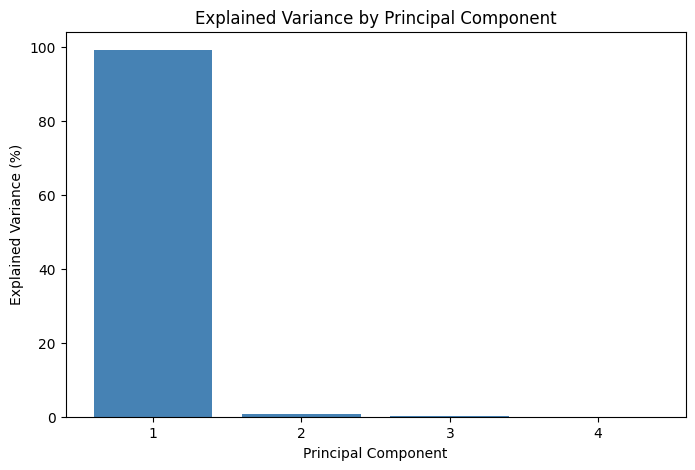

In [8]:
#plot for explained variance
components = range(1, len(explained_variance) + 1)
plt.figure(figsize=(8, 5))
plt.bar(
    components,
    explained_variance * 100,
    color='steelblue'
)
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')
plt.title('Explained Variance by Principal Component')
plt.xticks(components)
plt.show()

In [9]:
#cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)
print("Cumulative explained variance:")
for i, variance in enumerate(cumulative_variance):
    print(f"First {i+1} component(s): {variance * 100:.2f}%")

Cumulative explained variance:
First 1 component(s): 99.13%
First 2 component(s): 99.92%
First 3 component(s): 100.00%
First 4 component(s): 100.00%


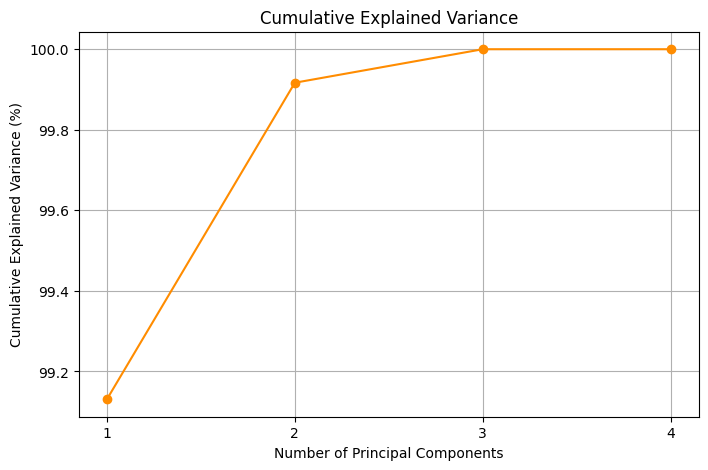

In [10]:
#plot for cumulative explained variance
plt.figure(figsize=(8, 5))
plt.plot(
    components,
    cumulative_variance * 100,
    marker='o',
    color='darkorange'
)
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.title('Cumulative Explained Variance')
plt.xticks(components)
plt.grid(True)
plt.show()

In [11]:
#reduce to 2 components
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)
pca_df = pd.DataFrame(
    X_pca_2d,
    columns=['PC1', 'PC2']
)
pca_df

,PC1,PC2
0,-3.050771,0.311925
1,-2.091874,-0.054476
2,-1.272359,-0.088048
3,-0.452843,-0.121621
4,0.306164,-0.251996
5,1.246696,-0.091962
6,2.187228,0.068072
7,3.127760,0.228106


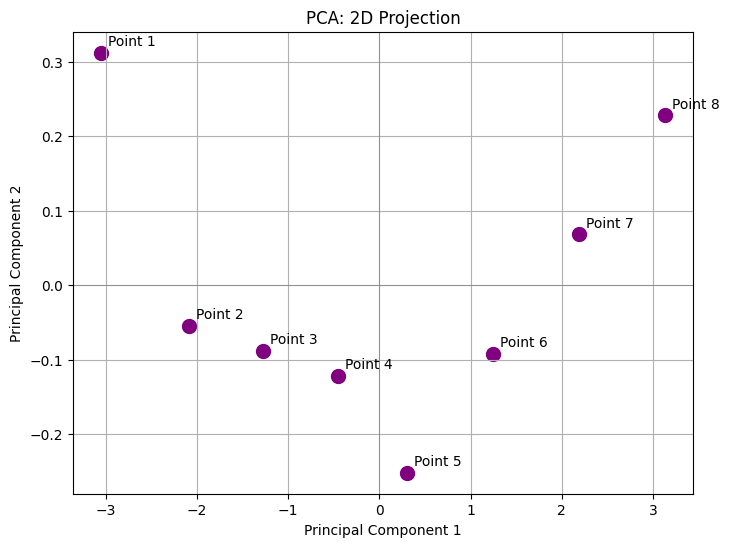

In [12]:
#visualize pca result
plt.figure(figsize=(8, 6))
plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    color='purple',
    s=100
)
for i in range(len(pca_df)):
    plt.annotate(
        f'Point {i+1}',
        (pca_df['PC1'][i], pca_df['PC2'][i]),
        xytext=(5, 5),
        textcoords='offset points'
    )
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA: 2D Projection')
plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)
plt.grid(True)
plt.show()

In [13]:
#examine pca components
components_df = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=['PC1', 'PC2', 'PC3', 'PC4']
)
print("PCA Component Loadings:")
display(components_df)

PCA Component Loadings:


,Height,Weight,Age,Score
PC1,0.499099,0.501908,4.970692e-01,0.501908
PC2,-0.589325,-0.100768,7.952283e-01,-0.100768
PC3,0.635292,-0.487786,3.471803e-01,-0.487786
PC4,-0.000000,0.707107,3.437705e-17,-0.707107


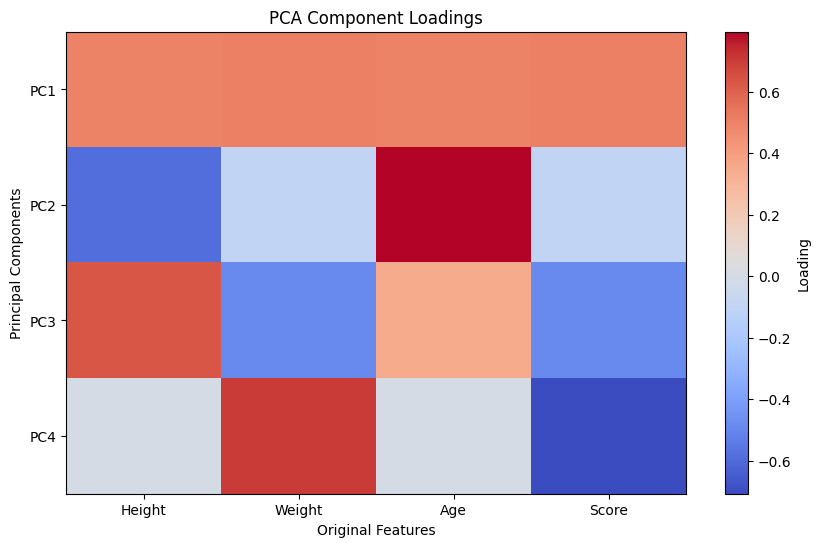

In [14]:
#visualize pca loading
plt.figure(figsize=(10, 6))
plt.imshow(
    components_df,
    cmap='coolwarm',
    aspect='auto'
)
plt.colorbar(label='Loading')
plt.xticks(
    range(len(X.columns)),
    X.columns
)
plt.yticks(
    range(len(components_df)),
    components_df.index
)
plt.xlabel('Original Features')
plt.ylabel('Principal Components')
plt.title('PCA Component Loadings')
plt.show()

In [15]:
#summary
print("Original number of features:", X.shape[1])
print("Reduced number of features:", X_pca_2d.shape[1])
print(
    f"\nPC1 explains "
    f"{pca_2d.explained_variance_ratio_[0] * 100:.2f}% of the variance."
)
print(
    f"PC2 explains "
    f"{pca_2d.explained_variance_ratio_[1] * 100:.2f}% of the variance."
)
print(
    f"Together, PC1 and PC2 explain "
    f"{pca_2d.explained_variance_ratio_.sum() * 100:.2f}% "
    f"of the total variance."
)

Original number of features: 4
Reduced number of features: 2

PC1 explains 99.13% of the variance.
PC2 explains 0.79% of the variance.
Together, PC1 and PC2 explain 99.92% of the total variance.
